# Day 6 (Task 3, first version): Classification Models

Same houses, new question: is a house **expensive** (above 15 million PKR) or not? That turns the
price into a yes or no label, so this is classification. Four models are compared on the
validation set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv("houses_clean.csv")

# one-hot encode the zone column (drop one level so the columns are not redundant)
df = pd.get_dummies(df, columns=["location_zone"], drop_first=True, dtype=int)

# same 70 / 15 / 15 split as Day 4
train, temp = train_test_split(df, test_size=0.30, random_state=42)
val, test = train_test_split(temp, test_size=0.50, random_state=42)
print(len(train), len(val), len(test))
df.head()

207 45 45


,area_marla,bedrooms,bathrooms,age_years,price_million_pkr,location_zone_Outskirts,location_zone_Suburban
0,12.5,5,5,11,23.58,0,0
1,5.5,1,1,14,5.05,1,0
2,10.5,3,2,15,16.35,0,0
3,18.5,4,3,23,23.27,0,1
4,11.5,3,2,22,15.20,0,1


In [2]:
THRESHOLD = 15   # million PKR, close to the overall median price

for part in (train, val, test):
    part["expensive"] = (part["price_million_pkr"] > THRESHOLD).astype(int)

features = [c for c in df.columns if c != "price_million_pkr"]
X_train, y_train = train[features], train["expensive"]
X_val, y_val = val[features], val["expensive"]

print("Share of expensive houses in train:", round(y_train.mean(), 3))

Share of expensive houses in train: 0.512


Scaling matters for Logistic Regression and KNN (distance and gradient steps are affected by the size
of the numbers), so those two go inside a pipeline with `StandardScaler`. Trees do not need scaling.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)
print("Logistic Regression val accuracy:", round(accuracy_score(y_val, logreg.predict(X_val)), 3))

Logistic Regression val accuracy: 0.911


### KNN: choosing k on the validation set

Best k: 1 | val accuracy: 0.889


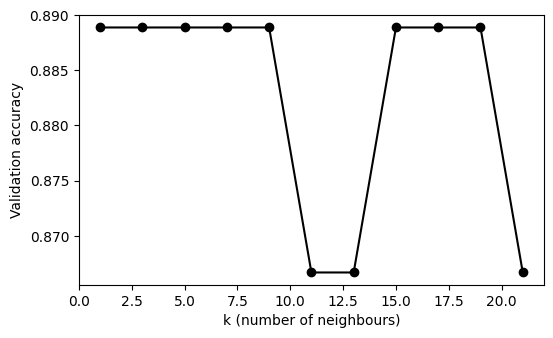

In [4]:
ks = list(range(1, 22, 2))
knn_scores = []
for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    m.fit(X_train, y_train)
    knn_scores.append(accuracy_score(y_val, m.predict(X_val)))

best_k = ks[int(np.argmax(knn_scores))]
print("Best k:", best_k, "| val accuracy:", round(max(knn_scores), 3))

plt.figure(figsize=(6, 3.5))
plt.plot(ks, knn_scores, marker="o", color="black")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Validation accuracy")
plt.show()

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)).fit(X_train, y_train)

### Decision tree: choosing max_depth

In [5]:
depths = range(1, 9)
tree_scores = []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    tree_scores.append((accuracy_score(y_train, t.predict(X_train)), accuracy_score(y_val, t.predict(X_val))))

for d, (tr, va) in zip(depths, tree_scores):
    print(f"depth {d}: train={tr:.3f}  val={va:.3f}")

best_depth = list(depths)[int(np.argmax([va for _, va in tree_scores]))]
tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X_train, y_train)
print("\nChosen max_depth:", best_depth)

depth 1: train=0.899  val=0.911
depth 2: train=0.899  val=0.911
depth 3: train=0.923  val=0.911
depth 4: train=0.947  val=0.911
depth 5: train=0.971  val=0.933
depth 6: train=0.981  val=0.867
depth 7: train=0.995  val=0.889
depth 8: train=1.000  val=0.889

Chosen max_depth: 5


In [6]:
# The rules the tree learned (a shallow version stays readable)
small_tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
print(export_text(small_tree, feature_names=features))

|--- area_marla <= 10.75
|   |--- area_marla <= 9.75
|   |   |--- bathrooms <= 2.50
|   |   |   |--- class: 0
|   |   |--- bathrooms >  2.50
|   |   |   |--- class: 0
|   |--- area_marla >  9.75
|   |   |--- location_zone_Outskirts <= 0.50
|   |   |   |--- class: 1
|   |   |--- location_zone_Outskirts >  0.50
|   |   |   |--- class: 0
|--- area_marla >  10.75
|   |--- area_marla <= 13.75
|   |   |--- bathrooms <= 1.50
|   |   |   |--- class: 0
|   |   |--- bathrooms >  1.50
|   |   |   |--- class: 1
|   |--- area_marla >  13.75
|   |   |--- area_marla <= 14.25
|   |   |   |--- class: 1
|   |   |--- area_marla >  14.25
|   |   |   |--- class: 1



### Random forest

In [7]:
forest = RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

## Comparison on the validation set

In [8]:
models = {
    "Logistic Regression": logreg,
    f"KNN (k={best_k})": knn,
    f"Decision Tree (depth={best_depth})": tree,
    "Random Forest": forest,
}
results = pd.Series({name: accuracy_score(y_val, m.predict(X_val)) for name, m in models.items()})
print(results.round(3).sort_values(ascending=False))

best_name = results.idxmax()
print("\nBest on validation:", best_name)
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_val, models[best_name].predict(X_val)))
print("\n", classification_report(y_val, models[best_name].predict(X_val), target_names=["not expensive", "expensive"]))

Decision Tree (depth=5)    0.933
Logistic Regression        0.911
KNN (k=1)                  0.889
Random Forest              0.867
dtype: float64

Best on validation: Decision Tree (depth=5)

Confusion matrix (rows = actual, columns = predicted):
[[20  2]
 [ 1 22]]

                precision    recall  f1-score   support

not expensive       0.95      0.91      0.93        22
    expensive       0.92      0.96      0.94        23

     accuracy                           0.93        45
    macro avg       0.93      0.93      0.93        45
 weighted avg       0.93      0.93      0.93        45



The validation set only has 45 houses, so one house changes accuracy by about 2%. Treat small gaps
between models as noise. Day 7 puts the final models on the test set once.